# Sales Prediction using Python

## Project Overview
This project predicts sales from advertising spend on TV, Radio and Newspaper using linear regression. It covers data cleaning, exploration, feature selection, model building and evaluation, and a what-if analysis of how changes in advertising spend affect sales, ending with recommendations for marketing strategy.

## Objectives
- Clean and prepare the advertising dataset
- Explore how each advertising channel relates to sales
- Select features and build a linear regression model to predict sales
- Evaluate the model's accuracy and check for overfitting
- Analyse how changes in advertising spend affect sales using what-if scenarios
- Present actionable insights for marketing strategy

## Dataset
**Source:** Kaggle, *Advertising* (`bumba5341/advertisingcsv`)

The dataset contains 200 records. Each record has the advertising spend on **TV**, **Radio** and **Newspaper** (the features) and the resulting **Sales** (the target). After dropping an unnecessary index column, 4 columns remain, with no missing values or duplicates.

## Contents
1. Import Libraries
2. Data Loading
3. Data Cleaning
4. Exploratory Data Analysis
5. Feature Selection
6. Train/Test Split
7. Linear Regression Model
8. Model Evaluation
9. Does Newspaper Improve the Model?
10. Impact of Advertising Changes
11. Key Findings
12. Recommendations
13. Limitations
14. Conclusion

## Import Libraries

In [29]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

## Data Loading

In [30]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bumba5341/advertisingcsv")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'advertisingcsv' dataset.
Path to dataset files: /kaggle/input/advertisingcsv


In [31]:
df = pd.read_csv(path + '/Advertising.csv')
df.head() # checking first few rows

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


## Data Cleaning

In [32]:
print(df.shape) # check data size
print(df.columns) # check column names

(200, 5)
Index(['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')


In [33]:
df.isnull().sum().sum() # checking missing values

np.int64(0)

In [34]:
df.duplicated().sum() # checking for duplicates

np.int64(0)

In [35]:
df.info() # checking data info

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [36]:
df.drop('Unnamed: 0', axis=1, inplace=True) # removing unnecessary column
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


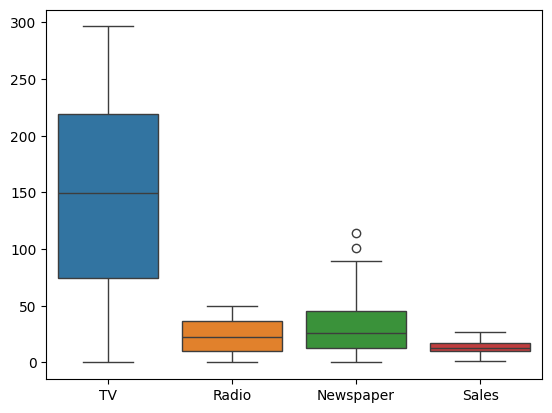

In [37]:
sns.boxplot(df[['TV', 'Radio', 'Newspaper', 'Sales']]) # checking outliers
plt.show()

#### Newspaper has a couple of higher points, around 100 or more.
#### Keeping the outliers because the dataset only has 200 rows.

## Exploratory Data Analysis

In [38]:
df.describe() # statistical summary

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


#### Sales averages about 14 (std 5.2). TV has the widest range (0.7 to 296.4) and Radio ranges from 0 to 49.6. Newspaper's maximum of 114 is far above its 75th percentile of 45, which is the outlier seen in the boxplot.

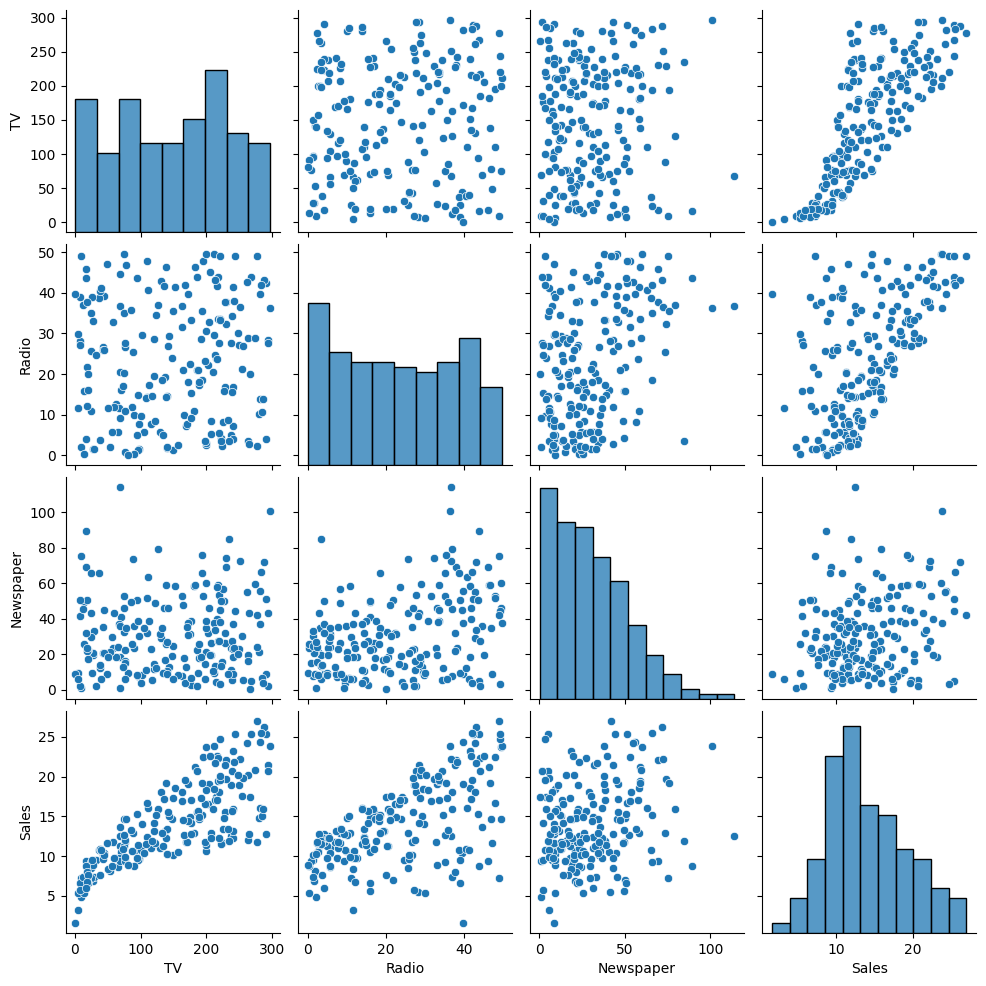

In [39]:
sns.pairplot(df) # distribution and skewness
plt.show()

#### Newspaper is right skewed; Sales is roughly symmetric

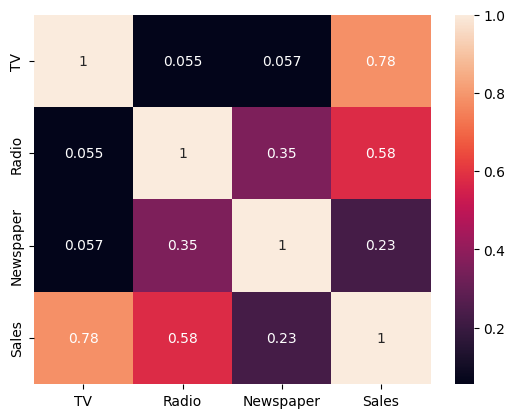

In [40]:
sns.heatmap(df.corr(), annot=True) #checking strongest correlation with the target variable (Sales)
plt.show()

#### Correlation with Sales: TV 0.78, Radio 0.58, Newspaper 0.23. TV is the strongest and Newspaper the weakest.

## Feature Selection

In [41]:
df.corr()['Sales'].sort_values(ascending=False)

,Sales
Sales,1.000000
TV,0.782224
Radio,0.576223
Newspaper,0.228299


In [42]:
x_vif = sm.add_constant(df[['TV', 'Radio', 'Newspaper']])
vif = pd.DataFrame({
    'feature': x_vif.columns,
    'VIF': [variance_inflation_factor(x_vif.values, i) for i in range(x_vif.shape[1])]
})
print(vif)

     feature       VIF
0      const  1.000000
1         TV  1.004611
2      Radio  1.144952
3  Newspaper  1.145187


#### Keeping all features because VIF shows no multicollinearity.

#### Scaling and encoding weren’t needed, since all features are numeric and linear regression doesn’t require scaling.

## Train/Test Split

In [43]:
x = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print(x_train.shape, x_test.shape)

(160, 3) (40, 3)


## Linear Regression Model

In [44]:
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [45]:
print("Intercept:", model.intercept_)

coef_df = pd.DataFrame({
    'feature': x.columns,
    'coefficient': model.coef_
})
print(coef_df)

Intercept: 2.979067338122629
     feature  coefficient
0         TV     0.044730
1      Radio     0.189195
2  Newspaper     0.002761


#### Per unit of spend, Radio has a larger effect, but TV spend varies much more across the data (std about 86 vs. about 15), so TV's total contribution to sales is larger and it correlates more strongly with Sales.



In [46]:
y_pred = model.predict(x_test)

## Model Evaluation

In [47]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.3f}")
print(f"MSE: {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2: {r2:.3f}")

MAE: 1.461
MSE: 3.174
RMSE: 1.782
R2: 0.899


#### R² of 0.899 means about 90% of variance is explained. RMSE of 1.78 is small next to the Sales std of 5.2.

#### Checking for overfitting

In [48]:
train_r2 = r2_score(y_train, model.predict(x_train))
test_r2 = r2_score(y_test, y_pred)

print(f"Train R2: {train_r2:.3f} | Test R2: {test_r2:.3f}")

Train R2: 0.896 | Test R2: 0.899


#### Train R² of 0.896 vs. test R² of 0.899, so there’s no overfitting.

#### Actual vs. Predicted Plot

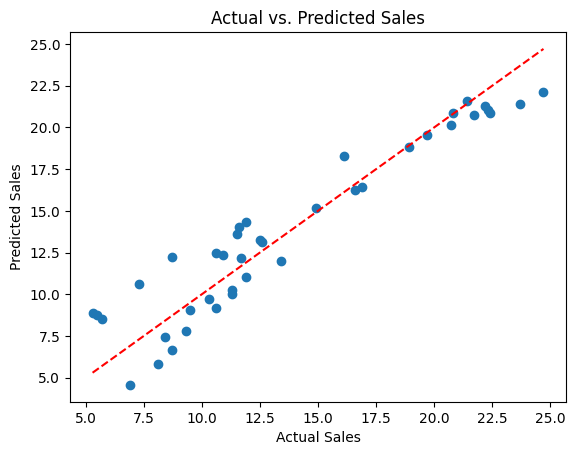

In [49]:
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs. Predicted Sales')
plt.show()

#### The points sit close to the red dashed line, so predicted sales track actual sales well, which matches the R² of about 0.90.

## Does Newspaper Improve the Model?

In [50]:
x_train2 = x_train.drop('Newspaper', axis=1)
x_test2 = x_test.drop('Newspaper', axis=1)

model2 = LinearRegression()
model2.fit(x_train2, y_train)
y_pred2 = model2.predict(x_test2)

print(f"With Newspaper    -> R²: {r2_score(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Without Newspaper -> R²: {r2_score(y_test, y_pred2):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred2)):.4f}")

With Newspaper    -> R²: 0.8994, RMSE: 1.7816
Without Newspaper -> R²: 0.9006, RMSE: 1.7714


#### R² went from 0.8994 to 0.9006 and RMSE from 1.78 to 1.77 after dropping it, **so the final model uses TV and Radio only.**

## Impact of Advertising Changes

In [51]:
print("Intercept:", model2.intercept_)
coef_df2 = pd.DataFrame({
    'feature': x_train2.columns,
    'coefficient': model2.coef_
})
print(coef_df2)

Intercept: 3.028255250783305
  feature  coefficient
0      TV     0.044728
1   Radio     0.190667


#### Holding the other channel fixed, one extra unit of TV spend adds about 0.045 units of sales and one extra unit of Radio adds about 0.19, roughly four times more per unit.

In [52]:
baseline = x_train2.mean().to_frame().T
base_pred = model2.predict(baseline)[0]
results = []
for channel in ['TV', 'Radio']:
  for pct in [10, 20]:
    scenario = baseline.copy()
    scenario[channel] = scenario[channel] * (1 + pct / 100)
    new_pred = model2.predict(scenario)[0]
    results.append({
            'channel': channel,
            'spend increase': f'{pct}%',
            'predicted sales': new_pred,
            'change': new_pred - base_pred,
            'change %': (new_pred - base_pred) / base_pred * 100
        })

scenario_df = pd.DataFrame(results)
print(f"Baseline predicted sales: {base_pred:.2f}")
print(scenario_df.round(2))

Baseline predicted sales: 14.10
  channel spend increase  predicted sales  change  change %
0      TV            10%            14.77    0.67      4.76
1      TV            20%            15.44    1.34      9.52
2   Radio            10%            14.54    0.44      3.09
3   Radio            20%            14.97    0.87      6.19


#### +10% TV gives +0.67 sales and +10% Radio gives +0.44. TV’s gain is bigger only because its average budget (147) is much larger than Radio’s (23).

In [53]:
for channel, coef in zip(x_train2.columns, model2.coef_):
    print(f"+10 units of spend on {channel}: {coef * 10:.2f} extra sales")

+10 units of spend on TV: 0.45 extra sales
+10 units of spend on Radio: 1.91 extra sales


In [54]:
coefs = dict(zip(x_train2.columns, model2.coef_))

shift = 10   # units of budget moved from TV to Radio
change = -shift * coefs['TV'] + shift * coefs['Radio']
print(f"Moving {shift} units of budget from TV to Radio changes predicted sales by {change:+.2f}")

Moving 10 units of budget from TV to Radio changes predicted sales by +1.46


#### +10 units gives +1.91 for Radio vs. +0.45 for TV. Shifting 10 units from TV to Radio gives +1.46.

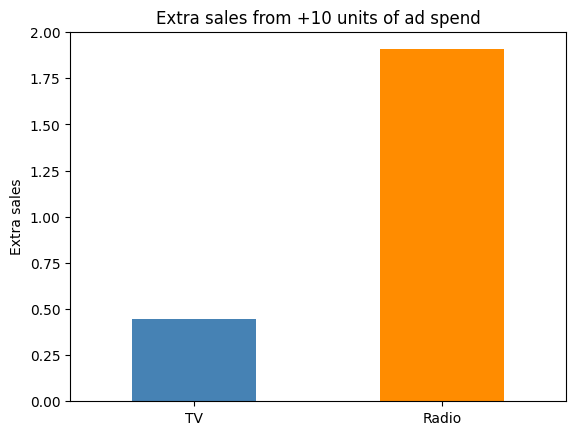

In [55]:
extra_sales = pd.Series(model2.coef_ * 10, index=x_train2.columns)

extra_sales.plot(kind='bar', color=['steelblue', 'darkorange'])
plt.ylabel('Extra sales')
plt.title('Extra sales from +10 units of ad spend')
plt.xticks(rotation=0)
plt.show()

#### Radio's bar is about four times taller than TV's (1.91 vs. 0.45), so the same extra budget buys far more sales on Radio.

In [56]:
new_plans = pd.DataFrame({'TV': [200, 185], 'Radio': [30, 45]},
                         index=['Plan A', 'Plan B'])
print(model2.predict(new_plans))

[17.69393358 19.88301802]


#### Both plans spend 230 units in total. Plan B puts 15 more units into Radio and 15 fewer into TV, and is predicted to sell about 19.88 versus 17.69 for Plan A. At the same budget, shifting spend from TV to Radio raises predicted sales. Radio stays at 45, inside the data range (max about 50), so the prediction is reliable.

## Key Findings

* Radio is the most efficient channel. Per 10 extra units of spend, Radio adds about 1.91 sales versus 0.45 for TV, roughly four times the return per unit of budget.
* TV is still a major sales driver overall. It correlates most strongly with Sales (0.78) because TV spend varies much more across the data (std about 86 vs. about 15 for Radio), so even a small per-unit effect adds up to a large contribution.
* Newspaper adds no measurable value. Its coefficient is close to zero (0.003) and removing it did not reduce accuracy.
* Reallocation helps. Moving 10 units of budget from TV to Radio is predicted to raise sales by about 1.46 without increasing total spend.
* The final model (TV + Radio) is accurate: test R² of about 0.90 and RMSE of about 1.77, with no sign of overfitting.

## Recommendations

* Move part of the budget from Newspaper (and possibly some TV) into Radio.
* Keep TV as the base channel but treat it as the lower-return channel per unit.
* Cut or test reducing Newspaper spending.

## Limitations

* The model is linear, so it assumes constant returns. Real advertising has diminishing returns, so don’t assume Radio keeps giving the same boost at much higher spend. Only trust the model within the spend ranges in the data (Radio goes up to about 50).
* The data has only 200 rows and shows correlation, not proven causation.
* TV and Radio may reinforce each other, which this simple model can’t capture. A TV × Radio interaction term or a Random Forest would be a good future improvement.
* The dataset has no platform or segment columns, so conclusions are at the channel level only.

## Conclusion

A linear regression model using TV and Radio spend predicts sales well (test R² of about 0.90, RMSE of about 1.77). Radio gives the highest return per unit of spend, TV is the main driver by volume, and Newspaper adds nothing. The main recommendation is to shift budget from Newspaper and TV into Radio, staying within the spend ranges seen in the data.